### 查询重构：如何处理结构化数据？
---
查询重构：这种检索策略聚焦在如何提高查询效率上，比如如何优化SQL语句

自查询  

* 适用于半结构化数据，一般用在向量数据库的元数据查询上
* 使用SelfQueryRetriever的检索器
* 核心是从元数据中查找信息

文本到SQL  

* 将自然输入重建为相应的SQL查询
* 使用自然语言来跑SQL语句

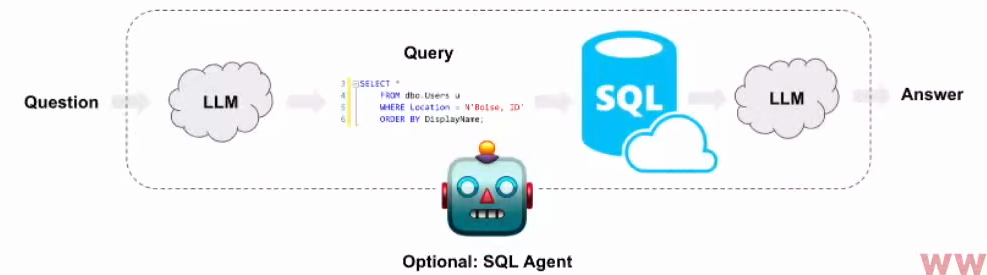

### 检索器：查询重构
---
* 用自然语言来查询SQL

### 查询SQL
---
- 步骤1：将问题转换为SQL查询，模型将用户输入转换为SQL查询。
- 步骤2：执行SQL查询，执行查询。
- 步骤3：回答问题，模型使用查询结果响应用户输入。

In [1]:
! pip install --upgrade --quiet langchain-community langchainhub langgraph

查看数据库

In [2]:
from langchain_community.utilities import SQLDatabase

db = SQLDatabase.from_uri("sqlite:///Chinook.db")
print(db.dialect)
print(db.get_usable_table_names())
db.run("SELECT * FROM Artist LIMIT 10;")

sqlite
['Album', 'Artist', 'Customer', 'Employee', 'Genre', 'Invoice', 'InvoiceLine', 'MediaType', 'Playlist', 'PlaylistTrack', 'Track']


"[(1, 'AC/DC'), (2, 'Accept'), (3, 'Aerosmith'), (4, 'Alanis Morissette'), (5, 'Alice In Chains'), (6, 'Antônio Carlos Jobim'), (7, 'Apocalyptica'), (8, 'Audioslave'), (9, 'BackBeat'), (10, 'Billy Cobham')]"

使用hub上预制的提示词

In [6]:
from langsmith import Client

client = Client()

query_prompt_template = client.pull_prompt(
    "langchain-ai/sql-query-system-prompt",
    dangerously_pull_public_prompt=True  
)

print("✅ 成功拉取 Prompt！\n")

# assert len(query_prompt_template.messages) == 1
query_prompt_template.pretty_print()

✅ 成功拉取 Prompt！

================================ System Message ================================

Given an input question, create a syntactically correct {dialect} query to run to help find the answer. Unless the user specifies in his question a specific number of examples they wish to obtain, always limit your query to at most {top_k} results. You can order the results by a relevant column to return the most interesting examples in the database.

Never query for all the columns from a specific table, only ask for a the few relevant columns given the question.

Pay attention to use only the column names that you can see in the schema description. Be careful to not query for columns that do not exist. Also, pay attention to which column is in which table.

Only use the following tables:
{table_info}

================================ Human Message =================================

Question: {input}


使用LCEL创建一个最简单的SQL查询

In [23]:
from typing_extensions import Annotated
from typing_extensions import TypedDict
from langchain_deepseek import ChatDeepSeek
from dotenv import load_dotenv
import os

load_dotenv()

model = ChatDeepSeek(
    model="deepseek-ai/DeepSeek-V4.1-Flash",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

# Define the state type
class State(TypedDict):
    question: str
    query: str
    result: str
    answer: str

# Define the output type
class QueryOutput(TypedDict):
    """Generated SQL query."""

    query: Annotated[str, ..., "Sysntactically valid SQL query."]

# Define the write_query function
import re

def write_query(state: State):
    """Generate SQL query to fetch information."""
    prompt = query_prompt_template.invoke(
        {
            "dialect": db.dialect,
            "top_k": 10,
            "table_info": db.get_table_info(),
            "input": state["question"],
        }
    )
    
    response = model.invoke(prompt)
    raw_content = response.content
    
    # ✅ 使用正则提取 SQL（兼容模型输出 ```sql ... ``` 的情况）
    match = re.search(r"```sql\n(.*?)\n```", raw_content, re.DOTALL)
    if match:
        sql_query = match.group(1).strip()
    else:
        sql_query = raw_content.strip()
        
    return {"query": sql_query}

sqlMessage = write_query({"question": "一共有多少个员工？"})
print(sqlMessage)

{'query': 'SELECT COUNT(*) AS EmployeeCount\nFROM Employee;'}


得到的SQL语句可以直接进行执行⚠此操作有风险

In [25]:
from langchain_community.tools import QuerySQLDatabaseTool

def execute_query(state: State):
    """Execute SQL query."""
    execute_query_tool = QuerySQLDatabaseTool(db=db)
    return {"result": execute_query_tool.invoke(state["query"])}

execute_query(sqlMessage)

{'result': '[(8,)]'}

封装到一个链里面

In [28]:
from langchain_core.runnables import RunnablePassthrough
from langchain_community.tools import QuerySQLDatabaseTool
import re

def execute_query(state: State):
    """Execute SQL query."""
    execute_query_tool = QuerySQLDatabaseTool(db=db)
    return {"result": execute_query_tool.invoke(state["query"])}

def write_query(state: State):
    """Generate SQL query to fetch information."""
    prompt = query_prompt_template.invoke(
        {
            "dialect": db.dialect,
            "top_k": 10,
            "table_info": db.get_table_info(),
            "input": state["question"],
        }
    )
    
    response = model.invoke(prompt)
    raw_content = response.content
    
    # ✅ 使用正则提取 SQL（兼容模型输出 ```sql ... ``` 的情况）
    match = re.search(r"```sql\n(.*?)\n```", raw_content, re.DOTALL)
    if match:
        sql_query = match.group(1).strip()
    else:
        sql_query = raw_content.strip()
        
    return {"query": sql_query}

# Define the chain to answer questions from SQL query
def answer_question(state: State):
    """Format answer based on the query result."""
    prompt = f"""Based on the SQL query:
        {state["query"]}

        And the query result:
        {state["result"]}

        Answer the user's question: {state["question"]}
        Provide a concise and informative response.
    """
    return {"answer": model.invoke(prompt).content}

# Create a full chain from question to answer
sql_chain = (
    RunnablePassthrough.assign(query=write_query)
    .assign(result=execute_query)
    .assign(answer=answer_question)
)

# Example usage
question = "获取销售额最高的5位员工及其销售总额"
response = sql_chain.invoke({"question": question})

print("Question", question)
print("\nGenerated SQL:")
print(response["query"])
print("\nExecution Result:")
print(response["result"])
print("\nAswer:")
print(response["answer"])

Question 获取销售额最高的5位员工及其销售总额

Generated SQL:
{'query': 'SELECT\n    e.EmployeeId,\n    e.FirstName,\n    e.LastName,\n    SUM(i.Total) AS TotalSales\nFROM Employee e\nJOIN Customer c ON c.SupportRepId = e.EmployeeId\nJOIN Invoice i ON i.CustomerId = c.CustomerId\nGROUP BY e.EmployeeId, e.FirstName, e.LastName\nORDER BY TotalSales DESC\nLIMIT 5;'}

Execution Result:
{'result': "[(3, 'Jane', 'Peacock', 833.04), (4, 'Margaret', 'Park', 775.4), (5, 'Steve', 'Johnson', 720.16)]"}

Aswer:
{'answer': '根据查询结果，销售额最高的员工如下（结果仅返回 3 条，说明满足条件的员工不足 5 位）：\n\n| 排名 | EmployeeId | 姓名 | 销售总额 |\n|---:|---:|---|---:|\n| 1 | 3 | Jane Peacock | 833.04 |\n| 2 | 4 | Margaret Park | 775.40 |\n| 3 | 5 | Steve Johnson | 720.16 |\n\n查询按 `TotalSales DESC` 排序并限制前 5 条；实际只有 3 位员工有匹配的客户/发票销售记录。'}
